# LeetCode #143: Reorder List

https://leetcode.com/problems/reorder-list/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force: Store in Array** | $O(n)$ | $O(n)$ |
| **Optimal: Find Middle + Reverse + Merge ★** | $O(n)$ | $O(1)$ |

`n` is the number of nodes. $O(n)$ time means each node is visited a fixed number of times, so a
list of 50,000 nodes takes a few hundred thousand steps. The difference is memory: $O(n)$ space
means an extra array with one slot per node, while $O(1)$ means a handful of pointer variables no
matter how long the list is.

A **linked list** is a chain of nodes where each node only knows the next one. You can't jump to
"the last node" or "the middle node" directly; you have to walk there from the front. That's what
makes this problem harder than it looks: the order wants the front and the back alternately, and
you can only walk forward.

---

## Understanding the Methods

### Brute Force: Store in Array
Walk the list once and put every node in an array, so you *can* jump to any position. Then take
nodes alternately from the two ends of the array and relink them. Simple, but the array costs one
slot per node.

### Optimal: Find Middle + Reverse + Merge ★
The target order `L0, Ln, L1, Ln-1, ...` is just the first half of the list interleaved with the
second half read backwards. So: find the middle (one pointer moves one step at a time while another
moves two, so when the fast one reaches the end the slow one is halfway), cut the list there,
reverse the second half by flipping its arrows, then zip the two halves together one node from each.

**Why this is better than the array:** same linear time, but every step only relinks existing
nodes, so no extra memory is needed.

**Constraints:**
* The number of nodes is in the range `[1, 5 * 10^4]`
* `1 <= Node.val <= 1000`

## Explain Like I'm a Newbie

### What the question is actually asking

Rearrange the list so it goes first, last, second, second-to-last, and so on. Don't change any
values; move the nodes themselves.

```
before:  1 -> 2 -> 3 -> 4 -> 5
after:   1 -> 5 -> 2 -> 4 -> 3
```

### The one idea you need: it's two halves zipped together

The awkward part is "last". In a singly linked list you can only walk forward, so every time you
want the next node from the back you'd have to walk the whole list again.

Look at the answer differently, though. Split the list in the middle:

```
first half:   1 -> 2 -> 3
second half:  4 -> 5         reversed:  5 -> 4
zip them:     1  5  2  4  3
```

Reversing the second half turns "take from the back" into "take from the front", and taking from
the front of a list is the one thing linked lists are good at.

### What that means in code

Three steps, each a standard linked-list move:

1. **Find the middle** with two pointers: `slow` moves one node at a time, `fast` moves two. When
   `fast` can't go further, `slow` is at the end of the first half.
2. **Cut, then reverse the second half.** Set `slow.next = None` so the first half really ends
   there, then walk the second half flipping each arrow to point backwards.
3. **Merge**: take one node from each half in turn, relinking as you go. Before you overwrite a
   node's `next`, save where it used to point, or you lose the rest of that half.

### Mistakes people make the first time

1. **Forgetting the cut.** Without `slow.next = None`, the end of the first half still points into
   the second half. Both LeetCode samples come out in the right order, `1 4 2 3` and `1 5 2 4 3`,
   but the last node then points back into the list, so anything that walks to the end loops
   forever.
2. **Overwriting `next` before saving it.** The merge needs two saved pointers per round, one for
   each half.
3. **Shifting indices in the array version.** Removing elements from an array while also counting
   positions from both ends goes wrong after the first pair: `[1,2,3,4]` comes out `1 4 3 2`.

### Things worth knowing

The function returns nothing; it rearranges the caller's list in place. A one-node list is already
in order, which is why the code returns early for it.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "The target order is the first half interleaved with the second half backwards. So I find the middle with slow and fast pointers, cut the list there, reverse the second half, and zip the two halves together. Three linear passes, O(n) time and O(1) extra space, no values copied. The thing I'd watch is the cut: miss it and the result has a cycle in it."

---

### I slide the problem across the table

`1 → 2 → 3 → 4 → 5` should become `1 → 5 → 2 → 4 → 3`, in place, and I've said you may not just swap values.

> **You:** "So the order alternates from the front and the back: first, last, second, second-to-last. I'm relinking nodes, not rewriting values, and there's no return value, I modify the list I'm given."

Then the clarifier I'm listening for:

> **You:** "Is it singly linked? So I can only walk forward?"

**"Yes, singly linked."** That's the question that matters. With a doubly linked list this is a two-pointer exercise; with a singly linked one, "the last node" costs a full walk every time you want it. I'd also accept "can I use extra memory?", to which I'll say **"try not to."** What I don't want is "can values be negative?" when the values are never compared.

---

### Now tell me what's actually hard about it

"I'll use slow and fast pointers" is a technique, not an explanation. I want to know what problem it solves here.

> **You:** "The hard part is the back of the list. I need the last node, then the second-to-last, and in a singly linked list I can only go forward. Doing that naively means walking to the end each time, which is O(n²), or putting every node in an array, which is O(n) memory."

Then the reframe:

> **You:** "But if I look at the answer, it's the first half `1 2 3` zipped with `5 4`, which is the second half reversed. Reversing a linked list is easy and in place. Once the second half is reversed, 'take from the back' becomes 'take from the front of the other list'."

Now the three steps have a reason. Finding the middle is how you split; reversing is how you get the back cheaply; merging is the interleave.

If you'd started by proposing the array of nodes, that's a fine stepping stone. Say it costs O(n) memory and ask whether that's acceptable. When I say no, the three-step version becomes your answer to a constraint I set, rather than a trick you remembered.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "Three blocks. Slow and fast pointers until fast can't take two more steps. Cut after slow and reverse from there with prev and cur. Then a merge loop: while the second half has nodes, save both nexts, splice the second node in after the first, and advance both."

> **You:** "The middle search visits about n/2 nodes for slow, the reversal visits n/2, the merge visits each node once. So linear. Memory is about six pointers. Nothing allocated."

---

### Now whiteboard it

```
slow, fast = head, head
while fast.next and fast.next.next:
    slow, fast = slow.next, fast.next.next
```

> **You:** "Checking `fast.next.next` and not just `fast.next` makes slow stop at the end of the first half. For odd lengths the middle node stays in the first half, which is where it belongs: it ends up last."

```
prev, cur = None, slow.next
slow.next = None
```

> **You:** "This cut is the line that matters. Without it the first half's tail still points into the second half, and after the merge the last node points back into the list."

If you skip it, the samples print in the right order and then never stop. If I don't hear a sentence about the cut, I'll ask you what `3.next` is when you're done.

```
while cur:
    nxt = cur.next
    cur.next = prev
    prev, cur = cur, nxt
```

> **You:** "Standard reversal: save the next node before I flip the arrow, otherwise I've lost the rest of the list."

```
first, second = head, prev
while second:
    tmp1, tmp2 = first.next, second.next
    first.next = second
    second.next = tmp1
    first, second = tmp1, tmp2
```

> **You:** "Loop on `second` because the second half is never longer than the first. Two saved pointers, one per half, because I overwrite both `next` fields in the same round."

---

### Walk me through it before you say you're done

> **You:** "`1 2 3 4 5`. Slow and fast start at 1; fast can jump to 3, so slow goes to 2; fast can jump to 5, slow goes to 3; fast has no next, stop. Cut after 3: first half `1 2 3`. Reverse `4 5` into `5 4`. Merge: 1 then 5, then 2 then 4, then second is empty and 3 is already where it should be, with its `next` set to null by the cut. `1 5 2 4 3`."

> **You:** "Even length, `1 2 3 4`: slow stops at 2, halves `1 2` and `4 3`, merge gives `1 4 2 3`, and the loop ends when second runs out, right after 3. A single node returns early, which is fine: it's already in order."

---

### Then tell me what it costs, before I ask

There's no faster approach; every node has to move. So the useful thing to volunteer is the contract:

> **You:** "This destroys the original order in place. If the caller still needs it, they'd have to copy first, which is the O(n) memory we avoided. And the middle step assumes I can hold two pointers into the same list at once. That's free in Python, C# or Go; in Rust the borrow checker won't let me have two mutable cursors, so the Rust version counts the length first and walks one cursor to the middle. Same split, one extra read-only pass."

That last point is the kind of thing I like hearing: you know where the algorithm and the language rub against each other.

---

### What would worry me

Reaching for an array of nodes and calling it done without noticing the memory cost. A reversal written from memory that drops the saved `next`. And most of all, a candidate who tests by printing the first four values, sees `1 4 2 3`, and doesn't notice the list no longer ends.

## Solutions

All four do the same three things: find the middle, cut and reverse the second half, then zip the halves. The comments mark the cut and the saved pointers, which are where this goes wrong.

### C#

In [ ]:
// Find Middle + Reverse + Merge O(n) time, O(1) space
public class Solution {
    public void ReorderList(ListNode head) {
        if (head?.next == null) return;   // 0 or 1 node: already in order
        // Find middle: fast moves two steps per slow step, so when fast can't go on,
        // slow is at the end of the first half (the middle node stays in the first half)
        var slow = head; var fast = head;
        while (fast.next != null && fast.next.next != null) {
            slow = slow.next; fast = fast.next.next;
        }
        // Cut after slow, then reverse the second half. The cut matters: without it the
        // first half's tail still points into the second half and the result has a cycle.
        ListNode prev = null; var cur = slow.next; slow.next = null;
        // Save next BEFORE flipping the arrow, or the rest of the list is lost
        while (cur != null) { var next = cur.next; cur.next = prev; prev = cur; cur = next; }
        // Merge: one node from each half in turn. The second half is never longer,
        // so loop on it. Save both nexts first, because both get overwritten.
        var first = head; var second = prev;
        while (second != null) {
            var tmp1 = first.next; var tmp2 = second.next;
            first.next = second; second.next = tmp1;
            first = tmp1; second = tmp2;
        }
    }
}

### Python

In [ ]:
# Find Middle + Reverse + Merge O(n) time, O(1) space
class Solution:
    def reorderList(self, head: 'Optional[ListNode]') -> None:
        if not head or not head.next:
            return   # 0 or 1 node: already in order
        # Find middle: fast moves two steps per slow step, so when fast can't go on,
        # slow is at the end of the first half (the middle node stays in the first half)
        slow, fast = head, head
        while fast.next and fast.next.next:
            slow = slow.next
            fast = fast.next.next
        # Cut after slow, then reverse the second half. The cut matters: without it the
        # first half's tail still points into the second half and the result has a cycle.
        prev, cur = None, slow.next
        slow.next = None
        while cur:
            nxt = cur.next    # save next BEFORE flipping the arrow, or the rest is lost
            cur.next = prev
            prev, cur = cur, nxt
        # Merge: one node from each half in turn. The second half is never longer,
        # so loop on it. Save both nexts first, because both get overwritten.
        first, second = head, prev
        while second:
            tmp1, tmp2 = first.next, second.next
            first.next = second
            second.next = tmp1
            first, second = tmp1, tmp2

### Go

In [ ]:
// Find Middle + Reverse + Merge O(n) time, O(1) space
func reorderList(head *ListNode) {
    if head == nil || head.Next == nil { return }   // 0 or 1 node: already in order
    // Find middle: fast moves two steps per slow step, so when fast can't go on,
    // slow is at the end of the first half (the middle node stays in the first half)
    slow, fast := head, head
    for fast.Next != nil && fast.Next.Next != nil {
        slow = slow.Next; fast = fast.Next.Next
    }
    // Cut after slow, then reverse the second half. The cut matters: without it the
    // first half's tail still points into the second half and the result has a cycle.
    var prev *ListNode
    cur := slow.Next
    slow.Next = nil
    // Save next BEFORE flipping the arrow, or the rest of the list is lost
    for cur != nil { next := cur.Next; cur.Next = prev; prev = cur; cur = next }
    // Merge: one node from each half in turn. The second half is never longer,
    // so loop on it. Save both nexts first, because both get overwritten.
    first, second := head, prev
    for second != nil {
        tmp1, tmp2 := first.Next, second.Next
        first.Next = second; second.Next = tmp1
        first, second = tmp1, tmp2
    }
}

### Rust

Rust won't let two mutable references (`slow` and `fast`) point into the same list at once, so this version counts the nodes with a read-only walk and then moves a single cursor `(len - 1) / 2` steps, which lands on the same node `slow` would. The reversal and merge then follow the other three exactly.

In [ ]:
// Find Middle + Reverse + Merge O(n) time, O(1) space
impl Solution {
    pub fn reorder_list(head: &mut Option<Box<ListNode>>) {
        // Count the nodes with a read-only walk (Rust can't hold two mutable
        // cursors, slow and fast, into the same list at once)
        let mut len = 0usize;
        let mut p = head.as_ref();
        while let Some(node) = p {
            len += 1;
            p = node.next.as_ref();
        }
        if len < 3 { return; }   // 1 or 2 nodes: already in order

        // Walk to the end of the first half: the same node slow/fast would stop on
        // (the middle node stays in the first half)
        let mut mid = head.as_mut().unwrap();
        for _ in 0..(len - 1) / 2 {
            mid = mid.next.as_mut().unwrap();
        }

        // Cut after mid, then reverse the second half. The cut matters: without it the
        // first half's tail would still own the second half.
        let mut cur = mid.next.take();
        let mut prev: Option<Box<ListNode>> = None;
        while let Some(mut node) = cur {
            cur = node.next.take();   // save next BEFORE flipping the arrow
            node.next = prev;
            prev = Some(node);
        }

        // Merge: one node from each half in turn. The second half is never longer,
        // so stop when it runs out.
        let mut first = head.as_mut();
        let mut second = prev;
        while let Some(node) = first {
            match second {
                Some(mut s) => {
                    second = s.next.take();      // rest of the second half
                    s.next = node.next.take();   // s now points at the rest of the first half
                    node.next = Some(s);         // splice s in after node
                    first = node.next.as_mut().unwrap().next.as_mut();
                }
                None => break,
            }
        }
    }
}

## Example Scenarios

### 1. Common Case — Even Length
**Input:** `head=[1,2,3,4]`

`slow` stops at 2, so the halves are $1 \to 2$ and $3 \to 4$. Reversing the second gives
$4 \to 3$, and zipping one node from each gives $1 \to 4 \to 2 \to 3$. **Output:** `[1,4,2,3]`

### 2. Slightly Complex — Odd Length
**Input:** `head=[1,2,3,4,5]`

The middle node 3 stays with the first half $1 \to 2 \to 3$. The second half reverses to
$5 \to 4$, the zip runs out of second-half nodes after 4, and 3 is left at the end, already pointing
at nothing thanks to the cut. **Output:** `[1,5,2,4,3]`

### 3. Edge Case: Time Factor — Single Node
**Input:** `head=[1]`

Not a slow input: every list costs about three passes over its nodes, so the real time worst case
is just the longest list. A single node returns before any of that runs. **Output:** `[1]`

### 4. Edge Case: Space Factor — Two Nodes
**Input:** `head=[1,2]`

Memory is a few pointers for any length, so no input is worse than another here. Two nodes run
the whole routine for no change: `slow` stays on 1, reversing the lone 2 does nothing, and the merge
puts 2 back after 1. The Rust version returns as soon as it has counted them. **Output:** `[1,2]`

### 5. Almost-Impossible but Plausible — Longer Even Length
**Input:** `head=[1,2,3,4,5,6]`

Halves $1 \to 2 \to 3$ and $4 \to 5 \to 6$; the second reverses to $6 \to 5 \to 4$ and the zip
gives $1 \to 6 \to 2 \to 5 \to 3 \to 4$. Forget the cut and the order printed is the same, but 4
then points back at 4: the list never ends. **Output:** `[1,6,2,5,3,4]`

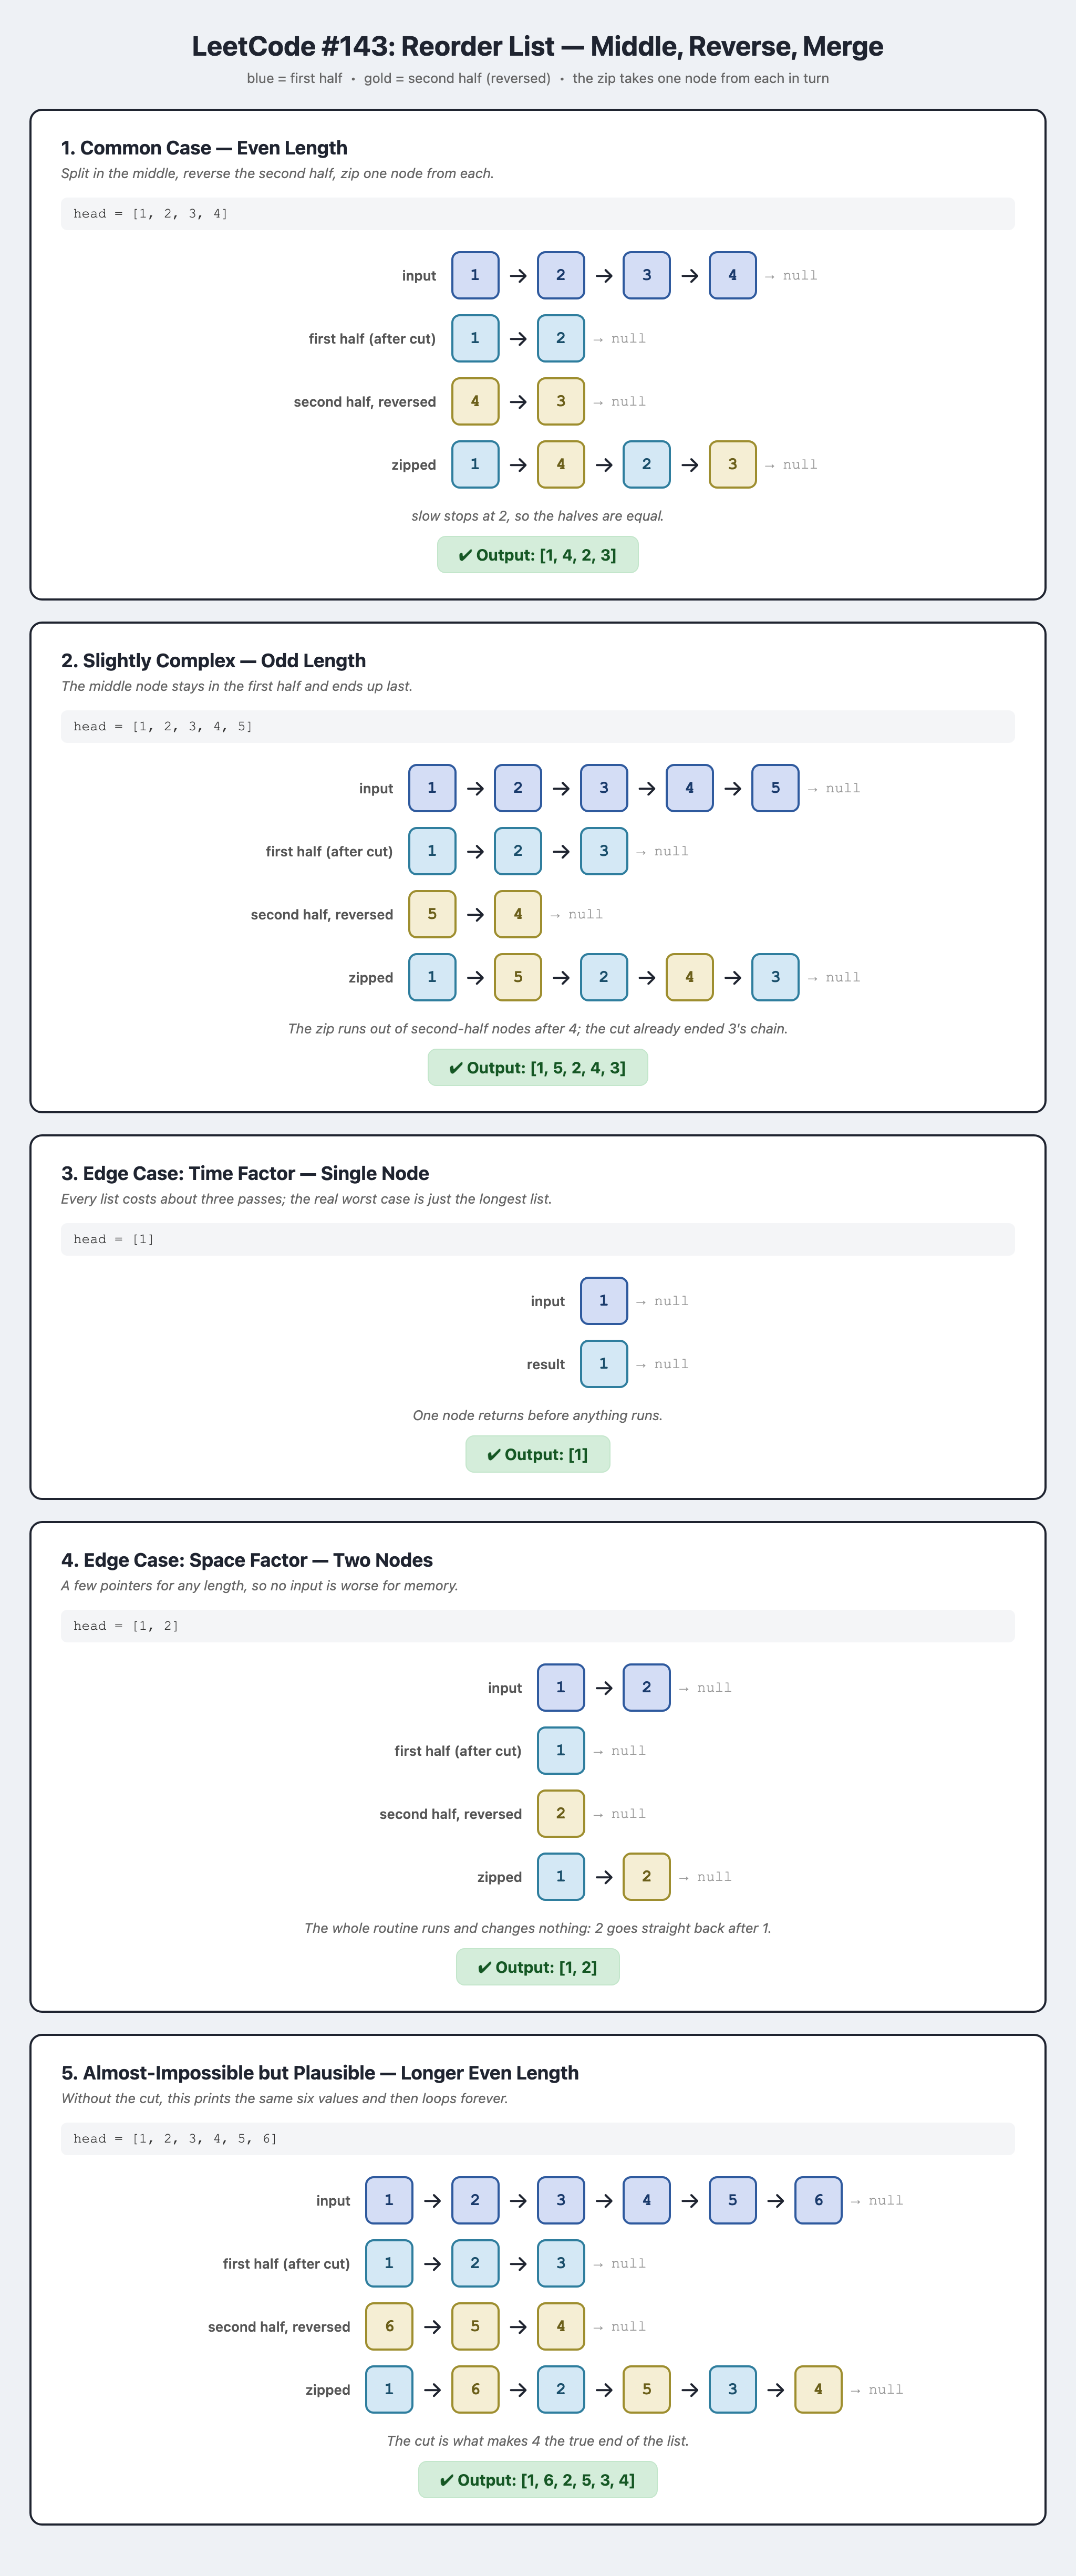

## Watch It Run

*Watch the cut after node 3: it's one line, and it's what stops the finished list from pointing back into itself.*

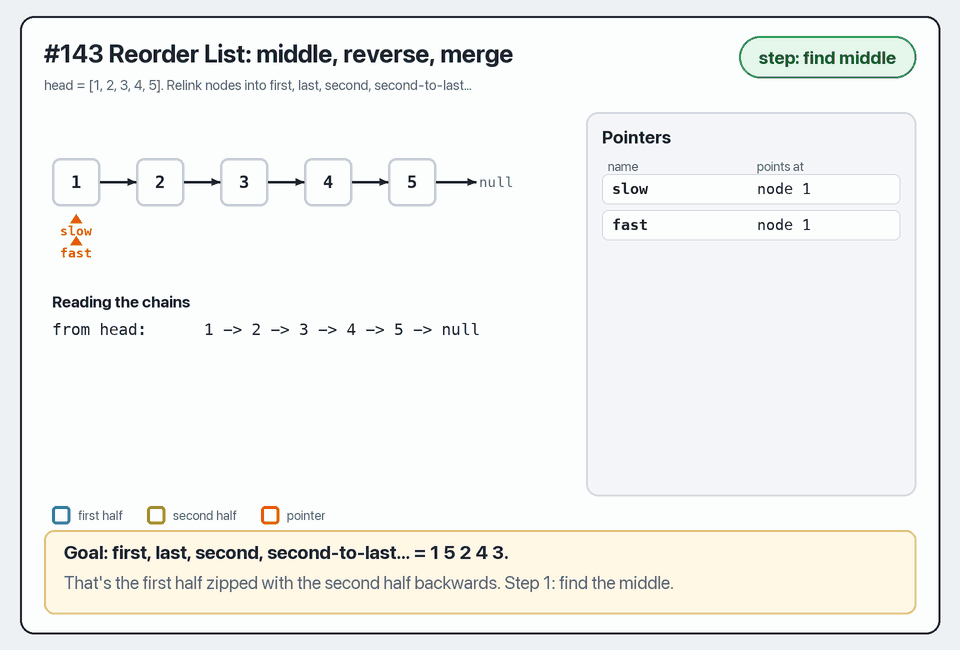